# Exploring the body from Python

This notebook talks to the bot (the **body**) through its HTTP API, with `brain/body.py`.
It only *calls* the API: the bot itself runs in another terminal.

**Before running it**
1. Start the server: `./server/run.sh`
2. Start the bot in API mode: `cd bot && node --env-file=../.env bot.js serve`
   (it prints `[api] ready on http://127.0.0.1:3000`)
3. Run the cells from top to bottom.

**Where is the bot?** After the in-game tests it stays in the test arena (high up, around
x=1000, z=1000, an empty stone floor surrounded by invisible walls): `find` and `mine` find nothing
there. To explore real terrain, type in the **server console** (the terminal of `run.sh`):
`spreadplayers 0 0 50 500 false Agent` (random place) or `tp Agent <x> <y> <z>`.

Everything the bot does here is logged to `data/dev/` (development data, disposable).
Skills are described in `bot/src/skills/catalogue.js`, the journal format in `docs/journal.md`.

## 1. Connect to the body

In [14]:
import json
import pathlib
import sys

# Make `brain` importable when the notebook runs from notebooks/
ROOT = (
    pathlib.Path.cwd().parent
    if pathlib.Path.cwd().name == "notebooks"
    else pathlib.Path.cwd()
)
sys.path.insert(0, str(ROOT))

from brain.body import Body, BodyBusy, BodyError, BodyUnreachable

body = Body()  # http://127.0.0.1:3000 (or API_PORT)
run = body.run()  # raises BodyUnreachable if the bot is not started
print("run:", run["run_id"], "| purpose:", run["purpose"], "| data:", run["data_dir"])
print("world:", run["world_id"], "| seed:", run["world_seed"], "| game:", run["game"])

run: run-20261019-085250-f3d7 | purpose: dev | data: /Users/tombourdareau/Projects/mc-agent/data/dev
world: localhost:25565 | seed: 4061568074923464531 | game: {'difficulty': 'peaceful', 'game_mode': 'survival', 'dimension': 'overworld', 'tick_rate': 20, 'view_distance': 3, 'simulation_distance': 3}


## 2. The skill catalogue
What the LLM will read: each skill's description, its parameters (JSON Schema) and its failure reasons.

In [15]:
catalogue = body.skills()
for name, entry in catalogue["skills"].items():
    params = entry["parameters"]["properties"]
    required = entry["parameters"].get("required", [])
    args = ", ".join(p + ("" if p in required else "?") for p in params)
    print(f"{name:12} ({entry['kind']:9}) {name}({args})")

catalogue version 3
move_to      (primitive) move_to(x, y, z, range?)
break_block  (primitive) break_block(x, y, z)
place_block  (primitive) place_block(item, x, y, z)
craft        (primitive) craft(item, count?)
eat          (primitive) eat(food?)
find         (question ) find(target, count?, max_distance?)
scan         (question ) scan(radius?)
explore      (primitive) explore(direction, distance?)
mine         (shortcut ) mine(block, count?)


In [16]:
# One skill in detail: change the name to look at another one
entry = catalogue["skills"]["mine"]
print(entry["description"], "\n")
print("parameters:", json.dumps(entry["parameters"]["properties"], indent=2))
print("failure reasons:")
for reason, meaning in entry["reasons"].items():
    print(f"  {reason:16} {meaning}")

Shortcut: get `count` blocks of a type (find then break_block, repeated). Moves on to other blocks if one is unreachable. Only succeeds if the items are in the inventory. 

parameters: {
  "block": {
    "type": "string",
    "description": "block name, e.g. 'oak_log'"
  },
  "count": {
    "type": "integer",
    "description": "number of blocks",
    "default": 1
  }
}
failure reasons:
  unknown_block    this name is not a block
  invalid_args     count is not an integer >= 1
  block_not_found  no block of this type within 32 blocks: try explore
  partial          fewer blocks than requested (details.dug)
  no_path          blocks exist but none is reachable
  no_tool          this block requires a tool (details.tools)
  unbreakable      unbreakable block
  not_loaded       area not loaded
  dig_failed       a block did not break
  not_collected    blocks broken but items not picked up


## 3. The state
`body.state()` returns the full state (`observe` on the Node side): body, inventory, world,
entities, notable blocks, and an 11x11x11 grid of blocks around the feet.
The LLM will not read it raw: the brain will render a short text from it. `summarize` below is a
first idea of such a rendering.

In [17]:
state = body.state()
print("fields:", ", ".join(state))

fields: position, yaw, pitch, velocity, on_ground, in_water, in_lava, on_fire, health, food, deaths, food_saturation, oxygen, xp_level, effects, inventory, inventory_slots, held_slot, held_item, armor, off_hand, game_mode, difficulty, dimension, biome, biome_id, light, sky_light, time_of_day, day, moon_phase, raining, thunder, entities, block_below, block_front, notable_blocks, notable_truncated, blocks


In [18]:
def summarize(s):
    """A short human-readable view of the state (a first draft of what the LLM could read)."""
    x, y, z = s["position"]
    lines = [
        f"position ({x:.1f}, {y:.1f}, {z:.1f}), health {s['health']}/20, food {s['food']}/20",
        f"time of day {s['time_of_day']} (day {s['day']}), raining {s['raining']}, difficulty {s['difficulty']}",
        f"inventory: {s['inventory'] or 'empty'}",
        f"holding: {s['held_item']['name'] if s['held_item'] else 'nothing'}",
    ]
    near = [
        f"{e['name']} at {e['distance']}" + (" (hostile)" if e["hostile"] else "")
        for e in s["entities"][:5]
    ]
    lines.append("entities: " + (", ".join(near) or "none"))
    notable = [
        f"{n} x{v['r32']} (nearest {v['distance']})"
        for n, v in (s["notable_blocks"] or {}).items()
    ]
    lines.append("notable blocks within 32: " + (", ".join(notable) or "none"))
    return "\n".join(lines)


print(summarize(state))

position (173.5, 75.0, 349.5), health 20/20, food 20/20
time of day 4047 (day 0), raining False, difficulty peaceful
inventory: empty
holding: nothing
entities: chicken at 5.3
notable blocks within 32: copper_ore x324 (nearest 5.4), coal_ore x528 (nearest 6), iron_ore x47 (nearest 7.8), acacia_log x60 (nearest 8.3), oak_log x17 (nearest 11.9), gravel x596 (nearest 12.7), lapis_ore x17 (nearest 19.8), water x10 (nearest 30.6)


In [19]:
def grid_slice(s, dy=-1):
    """Top-down view of one layer of the block grid (dy=-1: the floor, 0: feet, 1: head).
    North (-z) is up, east (+x) is right, @ is the bot. Each block is shown by its first letter."""
    g = s["blocks"]
    R = g["radius"]
    size = 2 * R + 1
    rows = []
    for dz in range(-R, R + 1):
        row = ""
        for dx in range(-R, R + 1):
            index = (dy + R) * size * size + (dz + R) * size + (dx + R)
            cell = g["cells"][index]
            name = "?" if cell is None else g["palette"][cell]
            char = "." if name in ("air", "cave_air") else name[0]
            row += "@" if (dx, dz) == (0, 0) and dy in (0, 1) else char
        rows.append(row)
    return "\n".join(rows)


print("palette:", state["blocks"]["palette"])
print("floor (dy=-1):")
print(grid_slice(state, dy=-1))
print("feet level (dy=0):")
print(grid_slice(state, dy=0))

palette: ['stone', 'coal_ore', 'dirt', 'copper_ore', 'grass_block', 'air', 'short_grass', 'tall_grass']
floor (dy=-1):
ggggddddddd
sggggdddddd
.tggggddddd
s..gggddddd
.t.sggddddd
.st.ggddddd
..ssgggdddd
..s.gggdddd
..sggggdddg
.s..gggddgg
.s..ggggdgg
feet level (dy=0):
ts..ggggddd
..s.sgggggg
.t.tt.ggggg
...s.tggggg
.t..stggggg
..t.s@ggggg
....sssgggg
....sssgggg
.....s.ggg.
....t.sgg.s
......ssg.s


## 4. Questions (they change nothing in the world)
`find` and `scan` tell where things are. Change the target to anything: a block name
(`oak_log`, `stone`, `water`...), an entity name (`cow`, `zombie`...) or `hostile`.

In [20]:
r = body.execute("find", {"target": "oak_log", "count": 3})
print(r["success"], r["reason"])
print(json.dumps(r["details"], indent=2))

True ok
{
  "target": "oak_log",
  "matches": [
    {
      "x": 163,
      "y": 75,
      "z": 355,
      "distance": 11.9
    },
    {
      "x": 163,
      "y": 74,
      "z": 355,
      "distance": 11.9
    },
    {
      "x": 163,
      "y": 76,
      "z": 355,
      "distance": 11.9
    }
  ]
}


In [12]:
r = body.execute("scan", {"radius": 16})
print("blocks:", json.dumps(r["details"]["blocks"], indent=1))
print("entities:", json.dumps(r["details"]["entities"], indent=1))

blocks: {
 "copper_ore": {
  "count": 74,
  "nearest": [
   -57,
   42,
   92
  ]
 },
 "water": {
  "count": 477,
  "nearest": [
   -54,
   43,
   90
  ]
 },
 "iron_ore": {
  "count": 37,
  "nearest": [
   -57,
   46,
   96
  ]
 },
 "coal_ore": {
  "count": 41,
  "nearest": [
   -51,
   37,
   87
  ]
 },
 "gravel": {
  "count": 123,
  "nearest": [
   -52,
   49,
   98
  ]
 },
 "sand": {
  "count": 231,
  "nearest": [
   -58,
   52,
   96
  ]
 }
}
entities: {
 "husk": {
  "count": 2,
  "nearest": [
   -58.8,
   40,
   93.5
  ],
  "distance": 3.9
 },
 "parched": {
  "count": 1,
  "nearest": [
   -55.4,
   57,
   97.3
  ],
  "distance": 14.8
 }
}


## 5. Actions
Coordinates are absolute: compute them from the current position.
A failure in the game is a **normal result** (`success: False` + a `reason`), not an exception.

In [13]:
x, y, z = body.state()["position"]
r = body.execute("move_to", {"x": x + 5, "y": y, "z": z})  # 5 blocks east
print(r["success"], r["reason"], r["duration"], "s")
print(r["details"])

False timeout 60.001 s
{'error': 'timeout'}


In [14]:
# Mine the nearest logs (find + break_block, repeated). Fails with block_not_found if there is
# no log within 32 blocks: then try explore (next cell) and run this one again.
r = body.execute("mine", {"block": "oak_log", "count": 2})
print(r["success"], r["reason"], r["duration"], "s")
print(r["details"])

False block_not_found 0.007 s
{'dug': 0, 'collected': {}, 'unreachable': 0}


In [15]:
r = body.execute("explore", {"direction": "north", "distance": 30})
print(r["success"], r["reason"], r["details"])

False timeout {'error': 'timeout'}


In [16]:
# With logs in the inventory: planks (a 2x2 recipe, no table needed), then sticks
for item, count in [("oak_planks", 4), ("stick", 4)]:
    r = body.execute("craft", {"item": item, "count": count})
    print(item, r["success"], r["reason"], r["details"])
print("inventory:", body.state()["inventory"])

oak_planks False missing_ingredients {'item': 'oak_planks', 'count': 4}
stick False missing_ingredients {'item': 'stick', 'count': 4}
inventory: {}


## 6. Failures the LLM will have to handle

In [17]:
cases = [
    ("fly", {}),  # unknown skill
    ("move_to", {"x": "far"}),  # invalid arguments
    ("craft", {"item": "wooden_pickaxe"}),  # missing ingredients, or no crafting table
    (
        "break_block",
        {"x": 0, "y": -64, "z": 0},
    ),  # probably not loaded, or bedrock (unbreakable)
    ("eat", {}),  # not hungry, or nothing to eat
]
for name, args in cases:
    r = body.execute(name, args)
    print(f"{name:12} {str(args):36} -> {r['reason']:20} {r['details']}")

fly          {}                                   -> unknown_skill        {}
move_to      {'x': 'far'}                         -> invalid_args         {'x': 'far', 'range': 1}
craft        {'item': 'wooden_pickaxe'}           -> missing_ingredients  {'item': 'wooden_pickaxe', 'count': 1}
break_block  {'x': 0, 'y': -64, 'z': 0}           -> unbreakable          {'position': [0, -64, 0], 'block': 'bedrock'}
eat          {}                                   -> not_hungry           {'food_before': 20}


In [18]:
# Communication problems are exceptions (they are not for the LLM to handle)
try:
    Body(url="http://127.0.0.1:9").state()  # nobody listens there
except BodyUnreachable as e:
    print("BodyUnreachable:", e)

BodyUnreachable: the bot does not answer on http://127.0.0.1:9: is it started (bot.js serve)?


## 7. What the journal recorded
Every `execute` above wrote one line in `transitions.jsonl` (in the run's data folder).
A line holds the state before, a trace of what happened during the skill, the state after, and the result.

In [19]:
transitions_file = pathlib.Path(run["data_dir"]) / "transitions.jsonl"
mine_lines = [json.loads(l) for l in transitions_file.read_text().splitlines()]
mine_lines = [
    l for l in mine_lines if l.get("run_id") == run["run_id"]
]  # this run only
print(len(mine_lines), "transitions in this run")
for l in mine_lines[-10:]:
    print(
        f"seq {l['seq']:3} {l['skill']['name']:12} {l['reason']:18} {l['duration']:6.2f}s"
    )

12 transitions in this run
seq   2 move_to      timeout             60.00s  continuous=True
seq   3 mine         block_not_found      0.01s  continuous=True
seq   4 explore      timeout             60.00s  continuous=False
seq   5 craft        missing_ingredients   0.00s  continuous=True
seq   6 craft        missing_ingredients   0.00s  continuous=True
seq   7 fly          unknown_skill        0.00s  continuous=True
seq   8 move_to      invalid_args         0.00s  continuous=True
seq   9 craft        missing_ingredients   0.00s  continuous=True
seq  10 break_block  unbreakable          0.00s  continuous=True
seq  11 eat          not_hungry           0.00s  continuous=True


In [20]:
line = mine_lines[-1]  # change the index to look at another transition
print("top-level fields:", ", ".join(line))
trace = line["trace"]
if trace:
    print(
        "trace parts:",
        {
            k: (len(v["rows"]) if isinstance(v, dict) and "rows" in v else len(v))
            for k, v in trace.items()
            if k != "truncated"
        },
    )
    print("events:", [e["type"] for e in trace["events"]])
    print("actions sent:", [a["packet"] for a in trace["actions"]][:20])

top-level fields: schema_version, run_id, seq, source, wall_start, wall_end, tick_start, tick_end, continuous, discontinuities, interventions, interventions_before, skill, context, state, trace, next_state, success, reason, details, duration, timed_out, error
context (measured before acting): None
trace parts: {'events': 2, 'body': 9, 'actions': 0, 'blocks': 0, 'entities': 12}
events: ['damage', 'health_loss']
actions sent: []


In [21]:
# The body trajectory, tick by tick, with the control keys decoded
KEYS = [
    "forward",
    "back",
    "left",
    "right",
    "jump",
    "sprint",
    "sneak",
]  # bit 0 = forward...


def keys(bits):
    return "+".join(k for i, k in enumerate(KEYS) if bits & (1 << i)) or "-"


# The transition of this run with the longest trajectory
moves = sorted(
    (l for l in mine_lines if l["trace"]), key=lambda l: len(l["trace"]["body"]["rows"])
)
if moves:
    body_series = moves[-1]["trace"]["body"]
    print(
        "skill:",
        moves[-1]["skill"],
        "|",
        len(body_series["rows"]),
        "ticks | fields:",
        body_series["fields"],
    )
    for row in body_series["rows"][::5][
        :20
    ]:  # one row out of 5 (4 per second), at most 20
        ms, x, y, z, yaw, pitch, vx, vy, vz, on_ground, controls = row
        print(
            f"{ms:6} ms  ({x:8.2f}, {y:6.2f}, {z:8.2f})  on_ground={on_ground}  keys={keys(controls)}"
        )

skill: {'name': 'move_to', 'args': {'x': -51.5, 'y': 43, 'z': 92.5}, 'args_resolved': {'range': 1, 'x': -51.5, 'y': 43, 'z': 92.5}} | 1216 ticks | fields: ['ms', 'x', 'y', 'z', 'yaw', 'pitch', 'vx', 'vy', 'vz', 'on_ground', 'controls']
    41 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
   244 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
   421 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
   422 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
   523 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
   777 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  1030 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  1282 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  1532 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  1785 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  2038 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  2293 ms  (  -56.50,  43.00,    92.50)  on_ground=1  keys=-
  2547 ms  (  -56.50,  43.00,   

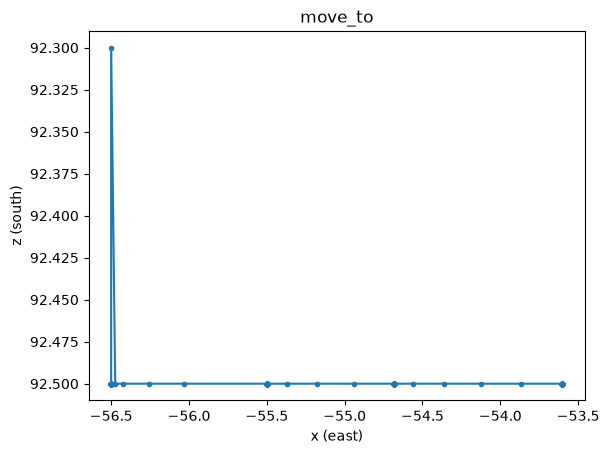

In [22]:
# Optional: plot the trajectory seen from above (needs matplotlib: uv add --dev matplotlib)
try:
    import matplotlib.pyplot as plt

    rows = moves[-1]["trace"]["body"]["rows"]
    plt.plot([r[1] for r in rows], [r[3] for r in rows], marker=".")
    plt.gca().invert_yaxis()  # north (-z) up
    plt.xlabel("x (east)")
    plt.ylabel("z (south)")
    plt.title(str(moves[-1]["skill"]["name"]))
    plt.show()
except ImportError:
    print("matplotlib is not installed: uv add --dev matplotlib")

## 8. The episode journal (Python side)
`brain/journal.py` will record the LLM's episodes. Here we write a fake one in a temporary file,
just to see the format (nothing is written to `data/`).

In [23]:
import tempfile
from brain.journal import EpisodeLog

tmp = pathlib.Path(tempfile.mkdtemp()) / "episodes.jsonl"
with EpisodeLog(path=tmp) as log:
    log.start(
        goal="craft a wooden pickaxe",
        model={"provider": "none", "name": "by hand"},
        system_prompt="(none)",
        tools=[],
        max_turns=1,
        run_id=run["run_id"],
    )
    turn = log.turn(
        new_messages=[], raw_response=None, plan=[{"skill": "scan", "args": {}}]
    )
    body.execute(
        "scan", {}, episode_id=log.episode_id, turn=turn
    )  # linked to the episode
    log.end(success=False, reason="max_turns", skill_calls=1)

for event in map(json.loads, tmp.read_text().splitlines()):
    print(
        event["seq"],
        event["type"],
        {k: v for k, v in event.items() if k in ("goal", "turn", "plan", "outcome")},
    )

0 episode_start {'goal': 'craft a wooden pickaxe'}
1 llm_turn {'turn': 0, 'plan': [{'skill': 'scan', 'args': {}}]}
2 episode_end {'outcome': {'success': False, 'reason': 'max_turns', 'turns': 1, 'skill_calls': 1, 'duration': 0.424, 'error': None}}


## 9. The agent loop with a fake LLM
`FakeLLM` (brain/llm.py) answers with plans written in advance, in order. It lets you run the
**real** agent loop (`brain/agent.py`) with the **real** bot, without any LLM: the plans are
really executed and everything is logged (episode + transitions), exactly as with a real LLM.

Each answer is written as a `plan` (list of skill calls, turned into one tool call per skill),
`done` (a goal_reached call), and optionally `missing_capability`. A plain string simulates a model that answers with
text instead of calling the tool.

In [9]:
from brain.agent import run_episode
from brain.llm import FakeLLM

fake = FakeLLM(
    [
        # Turn 0: look around, then try a craft that fails (no ingredients): the loop stops there
        {
            "plan": [
                {"skill": "scan", "args": {"radius": 16}},
                {"skill": "craft", "args": {"item": "wooden_pickaxe"}},
                {"skill": "find", "args": {"target": "oak_log"}},
            ],  # never run: the plan stopped before
            "done": False,
        },
        # Turn 1: a small model answering with text instead of the tool -> parse error, asked again
        "I think I should look for wood first.",
        # Turn 2: give up for this demo, with a missing capability
        {"plan": [], "done": True, "missing_capability": "nothing, this is a demo"},
    ]
)
outcome = run_episode("demo: craft a wooden pickaxe", body, fake, max_turns=5)
print(outcome)

{'episode_id': 'ep-20261019-075740-ca37', 'success': True, 'reason': 'done', 'skill_calls': 2, 'error': None}


In [10]:
# What the LLM "received" at each turn (system prompt, then the user messages)
print("=== system prompt (start) ===")
print(fake.calls[0][0]["content"][:800], "...")
for n, messages in enumerate(fake.calls):
    print(f"\n=== turn {n}: last message sent to the LLM ===")
    print(messages[-1]["content"])

=== system prompt (start) ===
You control a Minecraft bot through skills. You reach goals by chaining skills.

Rules:
- Answer ONLY by calling the tool propose_plans (or, if you cannot call tools, with its JSON:
  {"plan": [{"skill": "...", "args": {...}}], "missing_capability": "", "done": false}).
- A plan is a list of skill calls run in order. It stops at the first failure, and you then get
  the results and the new state to fix your plan.
- Coordinates are absolute block coordinates (x, y, z). North is -z, south +z, east +x, west -x.
  y is the height.
- Before acting on something you have not located, use find or scan. If find answers not_found,
  use explore, then search again.
- Do not repeat a call that just failed in the same way: read its reason and change the plan.
- When the goal is reached, answer with an  ...

=== turn 0: last message sent to the LLM ===
Goal: demo: craft a wooden pickaxe

Position: (-56, 45, 86), standing on granite.
Health 20/20, food 20/20.
Time: day.


In [11]:
# The episode as it was logged, next to the run's transitions
episodes_file = pathlib.Path(run["data_dir"]) / "episodes.jsonl"
events = [json.loads(l) for l in episodes_file.read_text().splitlines()]
events = [e for e in events if e["episode_id"] == outcome["episode_id"]]
for e in events:
    keep = {
        k: e[k]
        for k in (
            "turn",
            "plan",
            "parse_error",
            "missing_capability",
            "done",
            "outcome",
        )
        if k in e
    }
    print(e["seq"], e["type"], keep)

linked = [json.loads(l) for l in transitions_file.read_text().splitlines()]
linked = [l for l in linked if l.get("episode_id") == outcome["episode_id"]]
print(
    "\ntransitions of this episode:",
    [(l["turn"], l["skill"]["name"], l["reason"]) for l in linked],
)

0 episode_start {}
1 llm_turn {'turn': 0, 'plan': [{'skill': 'scan', 'args': {'radius': 16}}, {'skill': 'craft', 'args': {'item': 'wooden_pickaxe'}}, {'skill': 'find', 'args': {'target': 'oak_log'}}], 'parse_error': None, 'missing_capability': None, 'done': False}
2 llm_turn {'turn': 1, 'plan': None, 'parse_error': 'no propose_plans tool call and no JSON plan in the answer', 'missing_capability': None, 'done': False}
3 llm_turn {'turn': 2, 'plan': [], 'parse_error': None, 'missing_capability': 'nothing, this is a demo', 'done': True}
4 episode_end {'outcome': {'success': True, 'reason': 'done', 'turns': 3, 'skill_calls': 2, 'duration': 1.575, 'error': None}}


NameError: name 'transitions_file' is not defined

## 10. The same loop with a real LLM
Needs an LLM server speaking the OpenAI-compatible API, e.g. Ollama:
`brew install ollama`, then `ollama serve` (in a terminal) and `ollama pull qwen2.5:3b`.
Settings: `LLM_MODEL`, `LLM_BASE_URL` (default `http://127.0.0.1:11434/v1`), `LLM_TEMPERATURE`, `LLM_SEED`.
On natural terrain (not in the empty test arena) the goal below is reachable.

In [13]:
from brain.llm import LLMError, OpenAICompatibleLLM

llm = OpenAICompatibleLLM(model="qwen2.5:3b")  # or qwen2.5:7b, llama3.2:3b...
try:
    real = run_episode("craft a wooden pickaxe", body, llm, max_turns=6)
    print(real)
except LLMError as e:
    print("LLM not reachable:", e)

{'episode_id': 'ep-20261019-080152-860c', 'success': False, 'reason': 'max_turns', 'skill_calls': 11, 'error': None}
